<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Automated Atlas: NC County Example</div>
    </div>
</div>


In [75]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

<Axes: >

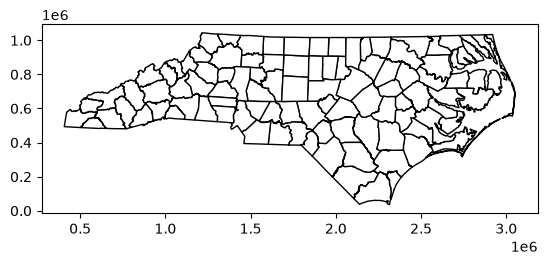

In [76]:

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties.plot(edgecolor="black", facecolor="white")

In [77]:
landfills = gpd.read_file("Active_Permitted_Landfills.geojson")

landfills = landfills.to_crs(nc_counties.crs)

print(nc_counties.columns)

print(nc_counties.crs)
print(landfills.crs)


landfills_by_county = gpd.sjoin(
    landfills,
    nc_counties[["NAME", "geometry"]],
    how="left",
    predicate="within"
)

landfill_counts = landfills_by_county.groupby("NAME").size()

nc_counties["landfill_count"] = (
    nc_counties["NAME"]
    .map(landfill_counts)
    .fillna(0)
    .astype(int)
)

print(nc_counties[["NAME", "landfill_count"]].head())

Index(['STATEFP', 'COUNTYFP', 'COUNTYNS', 'GEOIDFQ', 'GEOID', 'NAME',
       'NAMELSAD', 'STUSPS', 'STATE_NAME', 'LSAD', 'ALAND', 'AWATER',
       'geometry'],
      dtype='str')
EPSG:6543
EPSG:6543
        NAME  landfill_count
90  Columbus               2
91  Cherokee               1
92      Polk               0
93      Ashe               1
94      Dare               1


In [78]:
def county_map(county, ax):

    
    selected = nc_counties[nc_counties["NAME"] == county]

    selected.plot(
        ax=ax,
        edgecolor="black",
        facecolor="#7b9b90"
    )

    county_landfills = landfills_by_county[
        landfills_by_county["NAME"] == county
    ]

    county_landfills.plot(
        ax=ax,
        color="red",
        markersize=15
    )

    ax.set_title(f"{county} County Landfills")
    ax.set_axis_off()

    def locator_map(county, ax):

        selected = nc_counties[nc_counties["NAME"] == county]

        nc_counties.plot(
        ax=ax,
        edgecolor="gray",
        facecolor="white"
    )

        selected.plot(
        ax=ax,
        edgecolor="black",
        facecolor="#7b9b90"
    )

    ax.set_title("County Location in North Carolina")
    ax.set_axis_off()

In [79]:
def county_figure(county, pdf):

    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    count = nc_counties.loc[
        nc_counties["NAME"] == county,
        "landfill_count"
    ].iloc[0]

    fig.suptitle(
        f"{county} County Landfill Atlas",
        fontsize=18,
        fontweight="bold"
    )

    fig.text(
        0.5, 0.03,
        f"{county} County has {count} landfills.",
        ha="center",
        fontsize=14
    )

    plt.tight_layout(rect=[0, 0.07, 1, 0.93])

    pdf.savefig(fig)

    plt.close(fig)

In [80]:
with PdfPages("nc_landfill_atlas.pdf") as pdf:

    for county in nc_counties["NAME"]:
        county_figure(county, pdf)

print("Atlas created successfully!")

C:\Users\athen\AppData\Local\Temp\ipykernel_37016\1445023830.py:16: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  county_landfills.plot(
C:\Users\athen\AppData\Local\Temp\ipykernel_37016\1445023830.py:16: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  county_landfills.plot(
C:\Users\athen\AppData\Local\Temp\ipykernel_37016\1445023830.py:16: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  county_landfills.plot(
C:\Users\athen\AppData\Local\Temp\ipykernel_37016\1445023830.py:16: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  county_landfills.plot(
C:\Users\athen\AppData\Local\Temp\ipykernel_37016\1445023830.py:16: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  county_landfills.plot(
C:\Users\athen\AppData\Local\Temp\ipykernel_37016\1445023830

Atlas created successfully!
